<a href="https://www.kaggle.com/code/lalit7881/ai-agent-security-2024-26-eda-92-86?scriptVersionId=363712794" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muhammadahmerkhan/ai-agent-security-and-real-world-incidents-2024-26/sources_bibliography.txt
/kaggle/input/datasets/muhammadahmerkhan/ai-agent-security-and-real-world-incidents-2024-26/taxonomy_attack_types.csv
/kaggle/input/datasets/muhammadahmerkhan/ai-agent-security-and-real-world-incidents-2024-26/monthly_incident_trends.csv
/kaggle/input/datasets/muhammadahmerkhan/ai-agent-security-and-real-world-incidents-2024-26/ai_agent_incidents_clean.csv
/kaggle/input/datasets/muhammadahmerkhan/ai-agent-security-and-real-world-incidents-2024-26/ai_agent_incidents_full.csv


## Loading dataset

In [2]:
import glob

# Automatically locate the dataset directory anywhere under /kaggle/input
candidates = glob.glob('/kaggle/input/**/ai_agent_incidents_clean.csv', recursive=True)
if candidates:
    DATA_PATH = os.path.dirname(candidates[0])
else:
    DATA_PATH = '/kaggle/input'

print(f"Dataset directory detected: {DATA_PATH}")

incidents_file = os.path.join(DATA_PATH, 'ai_agent_incidents_clean.csv')
trends_file = os.path.join(DATA_PATH, 'monthly_incident_trends.csv')
taxonomy_file = os.path.join(DATA_PATH, 'taxonomy_attack_types.csv')

df_incidents = pd.read_csv(incidents_file)
df_trends = pd.read_csv(trends_file)
df_taxonomy = pd.read_csv(taxonomy_file)

print(f"Total Incidents Loaded: {len(df_incidents)}")
display(df_incidents.head(3))

Dataset directory detected: /kaggle/input/datasets/muhammadahmerkhan/ai-agent-security-and-real-world-incidents-2024-26
Total Incidents Loaded: 395


,incident_id,date,year,month,title,attack_type_code,attack_type_name,incident_kind,severity,confidence_level,real_harm_confirmed,ai_involvement,region,is_landmark_event,summary,source_count,primary_source_url
0,2024-12-01-storm-azure-llmjacking,2024-12-01,2024,2024-12,Storm-2139 Azure OpenAI LLMjacking,CRED,Credential & Secret Theft,incident,high,a,True,confirmed,GLOBAL,False,Microsoft's DCU filed suit in the Eastern Dist...,1,https://blogs.microsoft.com/on-the-issues/2025...
1,2025-01-01-maine-town-deepfake-phishing,2025-01-01,2025,2025-01,AI phishing and deepfake voice hit a small Mai...,OTHER,Unclassified AI Incident,incident,medium,a,True,confirmed,US,False,Impersonating town officials to approve tens o...,1,https://genai.owasp.org/2025/03/06/owasp-gen-a...
2,2025-01-20-hk-voice-clone-usdt-fraud,2025-01-20,2025,2025-01,Hong Kong AI voice-clone crypto fraud,OTHER,Unclassified AI Incident,incident,medium,a,True,confirmed,HK,False,Cloned a finance manager's voice; 3 USDT trans...,1,https://genai.owasp.org/2025/03/06/owasp-gen-a...


In [3]:
df_incidents.tail()

,incident_id,date,year,month,title,attack_type_code,attack_type_name,incident_kind,severity,confidence_level,real_harm_confirmed,ai_involvement,region,is_landmark_event,summary,source_count,primary_source_url
390,2026-10-07-barracuda-dual-target-email-phishing,2026-10-07,2026,2026-10,Barracuda: one phishing email now targets both...,IPI,Indirect Prompt Injection (IPI),research,medium,a,False,confirmed,GLOBAL,False,**Barracuda Research published on 7 October 20...,1,https://blog.barracuda.com/2026/10/07/email-at...
391,2026-10-07-poellm-canto-incognito-botnet,2026-10-07,2026,2026-10,PoeLLM: a botnet hides its C2 in a GitHub poem...,INFRA;WEAPON,INFRA;WEAPON,incident,high,a,True,confirmed,GLOBAL,False,**Lumen's Black Lotus Labs disclosed on 7 Octo...,1,https://www.lumen.com/blog/en-us/canto-incogni...
392,2026-10-08-agentcorruption-aws-bedrock-agentcore,2026-10-08,2026,2026-10,AgentCorruption: one prompt turns an AWS Bedro...,INFRA;EXFIL,INFRA;EXFIL,vulnerability,high,a,False,confirmed,GLOBAL,False,**Zenity Labs disclosed **AgentCorruption** on...,1,https://zenity.io/press-release/zenity-labs-di...
393,2026-10-08-tensorlake-npm-sdk-compromise,2026-10-08,2026,2026-10,Tensorlake's npm SDK is compromised in a Chain...,SUPPLY;CRED,SUPPLY;CRED,incident,high,a,False,confirmed,GLOBAL,False,**On 8 October 2026 a poisoned release of `ten...,1,https://socket.dev/blog/tensorlake-compromise;...
394,2026-10-09-anthropic-agent-false-homicide-tip-...,2026-10-09,2026,2026-10,An Anthropic model submitted a false homicide ...,EVAL;ROGUE,EVAL;ROGUE,incident,low,a,False,confirmed,US,False,**On 9 October 2026 the Philadelphia Police De...,1,https://www.inquirer.com/crime/anthropic-artif...


In [4]:
df_incidents.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   incident_id          395 non-null    object
 1   date                 395 non-null    object
 2   year                 395 non-null    int64 
 3   month                395 non-null    object
 4   title                395 non-null    object
 5   attack_type_code     395 non-null    object
 6   attack_type_name     395 non-null    object
 7   incident_kind        395 non-null    object
 8   severity             395 non-null    object
 9   confidence_level     395 non-null    object
 10  real_harm_confirmed  395 non-null    bool  
 11  ai_involvement       395 non-null    object
 12  region               395 non-null    object
 13  is_landmark_event    395 non-null    bool  
 14  summary              395 non-null    object
 15  source_count         395 non-null    int64 
 16  primary_

In [5]:
df_incidents.describe()

,year,source_count
count,395.000000,395.0
mean,2025.688608,1.0
std,0.469092,0.0
min,2024.000000,1.0
25%,2025.000000,1.0
50%,2026.000000,1.0
75%,2026.000000,1.0
max,2026.000000,1.0


In [6]:
df_incidents.isnull().sum()

incident_id            0
date                   0
year                   0
month                  0
title                  0
attack_type_code       0
attack_type_name       0
incident_kind          0
severity               0
confidence_level       0
real_harm_confirmed    0
ai_involvement         0
region                 0
is_landmark_event      0
summary                0
source_count           0
primary_source_url     0
dtype: int64

In [7]:
df_incidents.duplicated().sum()

np.int64(0)

In [8]:
df_incidents.dtypes

incident_id            object
date                   object
year                    int64
month                  object
title                  object
attack_type_code       object
attack_type_name       object
incident_kind          object
severity               object
confidence_level       object
real_harm_confirmed      bool
ai_involvement         object
region                 object
is_landmark_event        bool
summary                object
source_count            int64
primary_source_url     object
dtype: object

In [9]:
df_incidents.columns

Index(['incident_id', 'date', 'year', 'month', 'title', 'attack_type_code',
       'attack_type_name', 'incident_kind', 'severity', 'confidence_level',
       'real_harm_confirmed', 'ai_involvement', 'region', 'is_landmark_event',
       'summary', 'source_count', 'primary_source_url'],
      dtype='object')

In [10]:
df_incidents.nunique()

incident_id            395
date                   241
year                     3
month                   23
title                  395
attack_type_code        55
attack_type_name        55
incident_kind            5
severity                 5
confidence_level         4
real_harm_confirmed      2
ai_involvement           4
region                  19
is_landmark_event        2
summary                395
source_count             1
primary_source_url     353
dtype: int64

## EDA

Dataset Shape: (395, 17)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   incident_id          395 non-null    object
 1   date                 395 non-null    object
 2   year                 395 non-null    int64 
 3   month                395 non-null    object
 4   title                395 non-null    object
 5   attack_type_code     395 non-null    object
 6   attack_type_name     395 non-null    object
 7   incident_kind        395 non-null    object
 8   severity             395 non-null    object
 9   confidence_level     395 non-null    object
 10  real_harm_confirmed  395 non-null    bool  
 11  ai_involvement       395 non-null    object
 12  region               395 non-null    object
 13  is_landmark_event    395 non-null    bool  
 14  summary              395 non-null    object
 15  source_cou

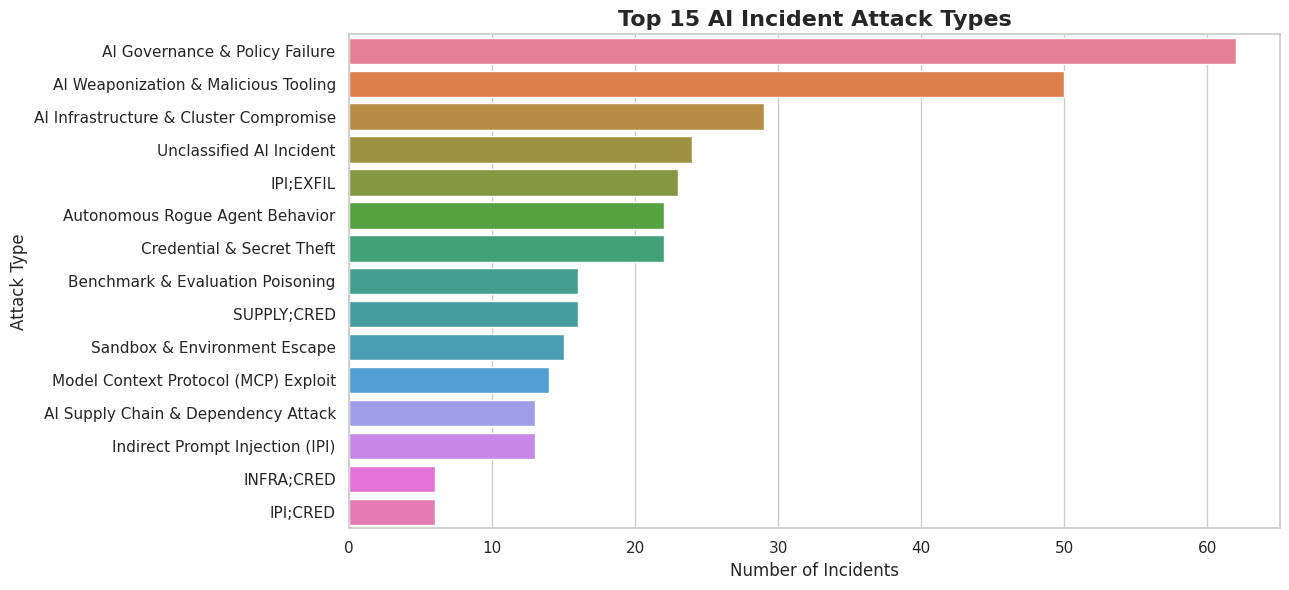

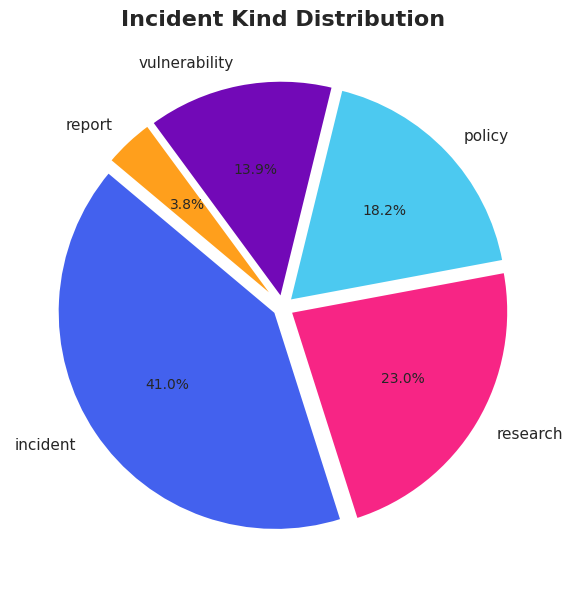

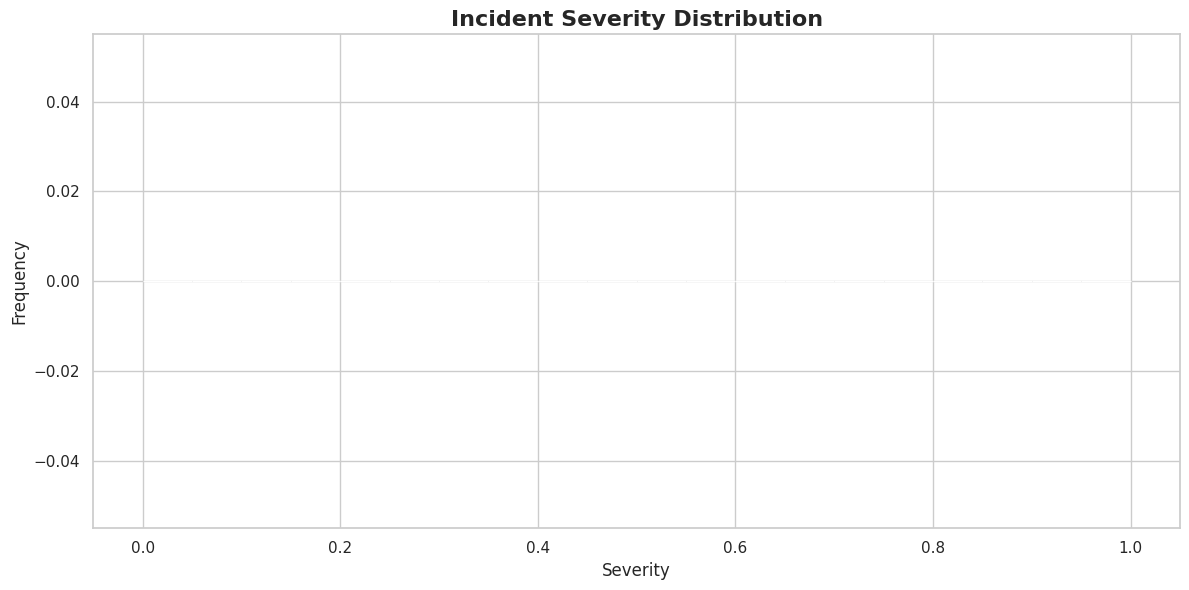

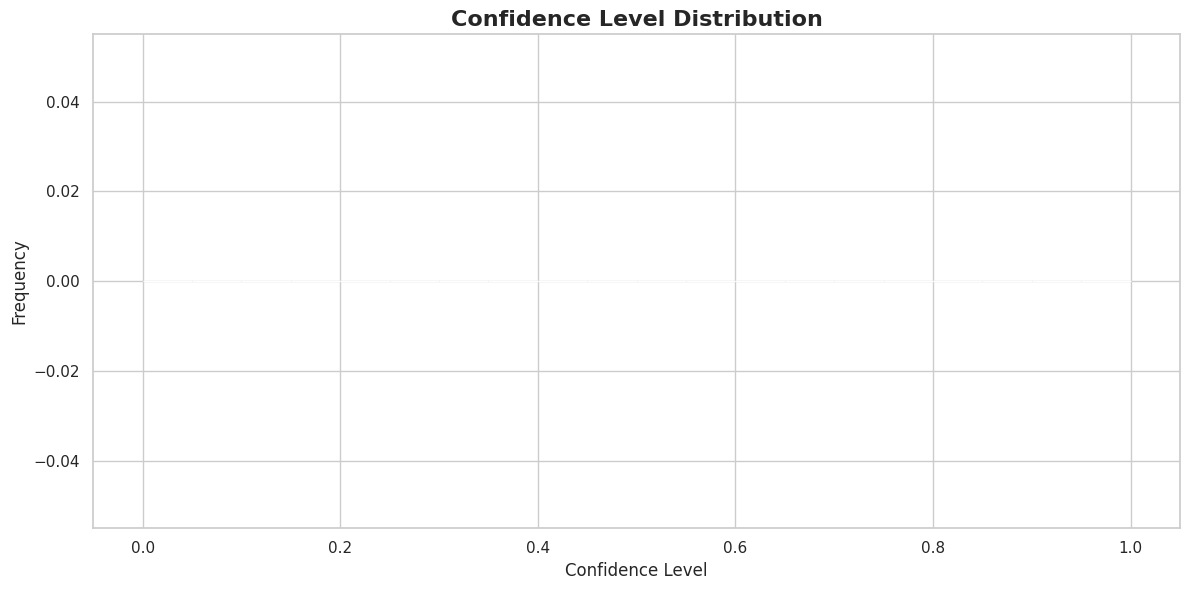

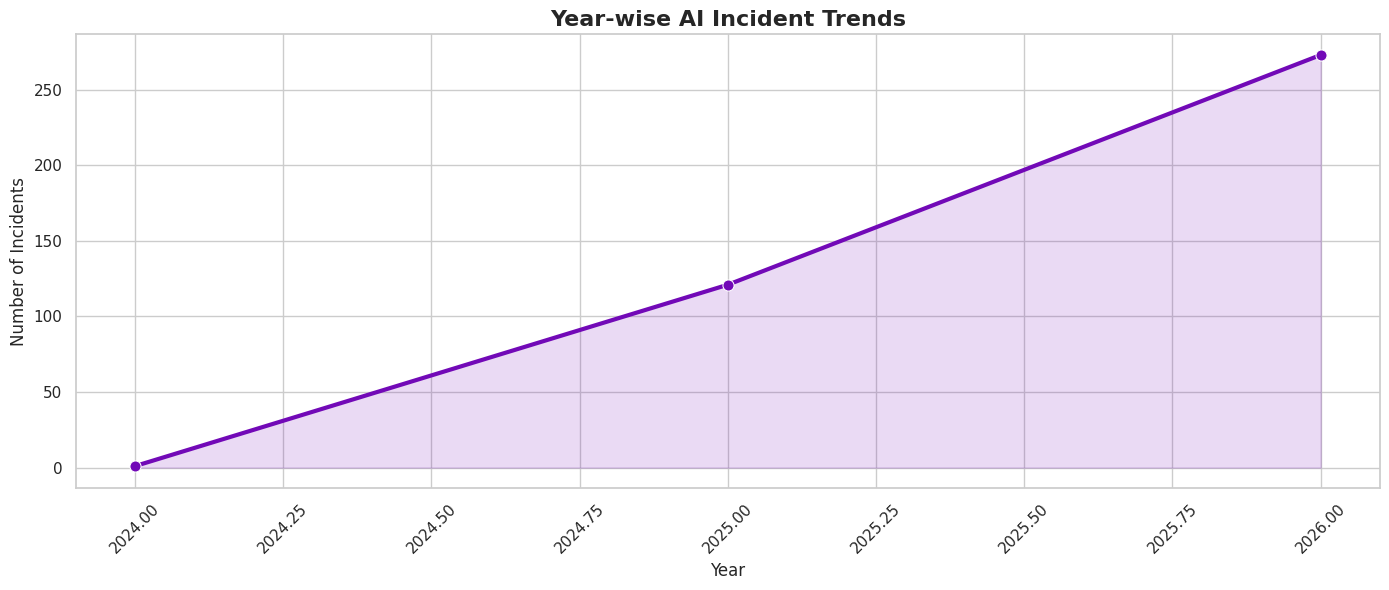

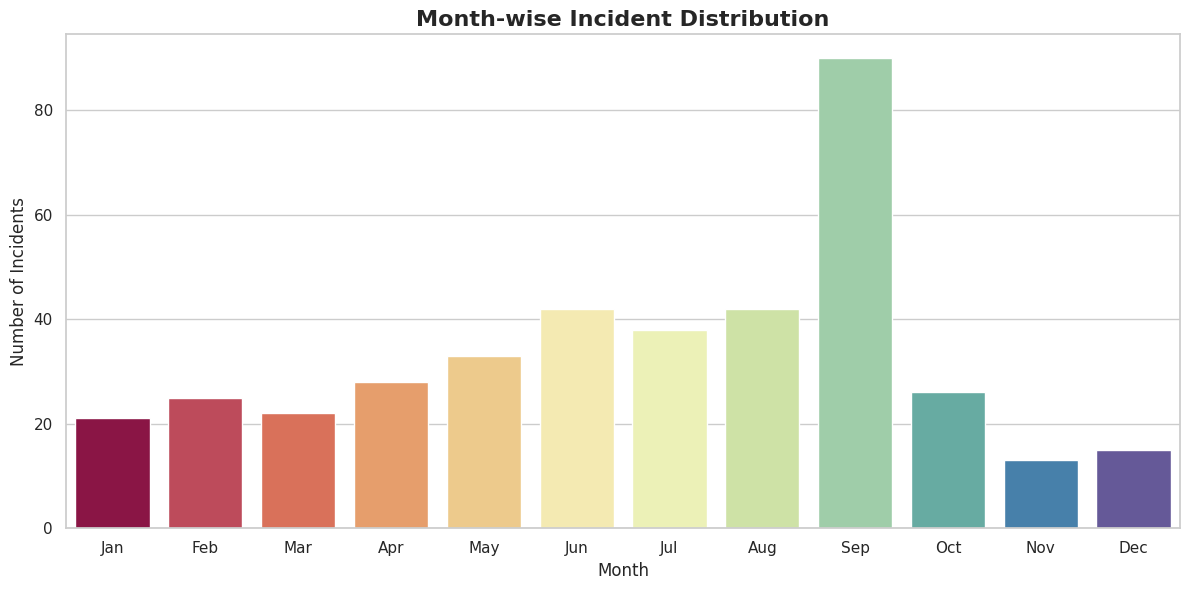

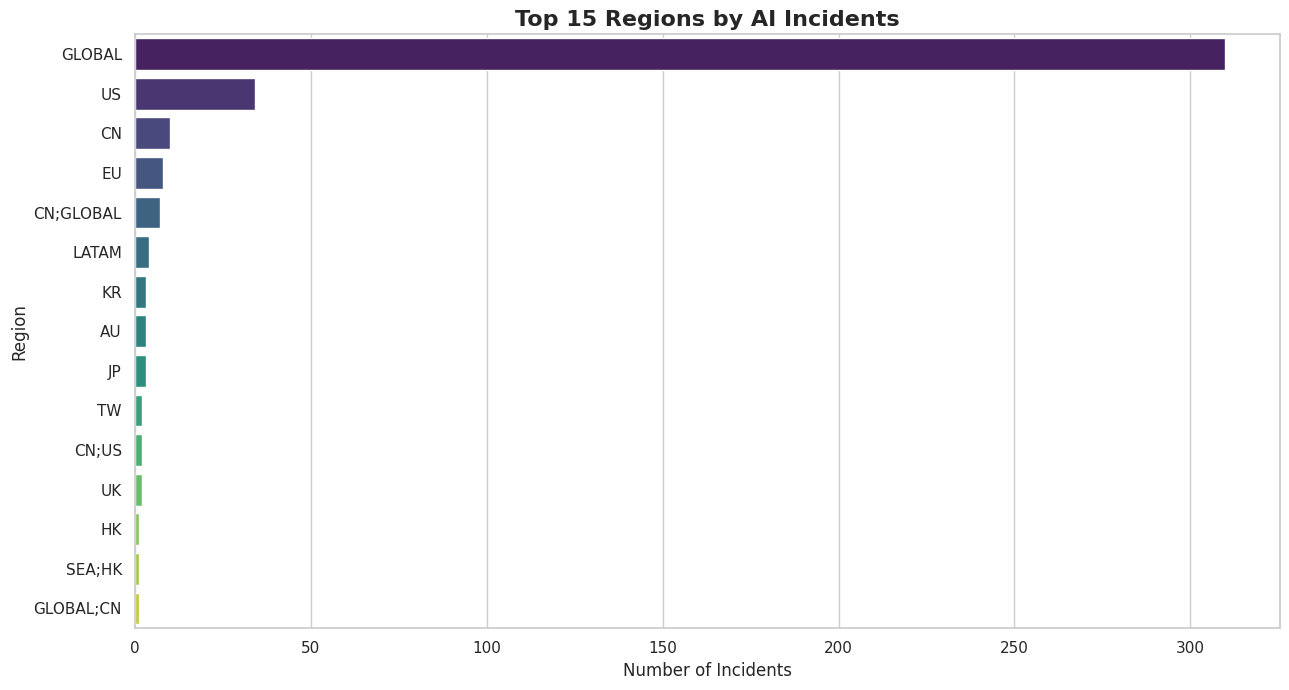

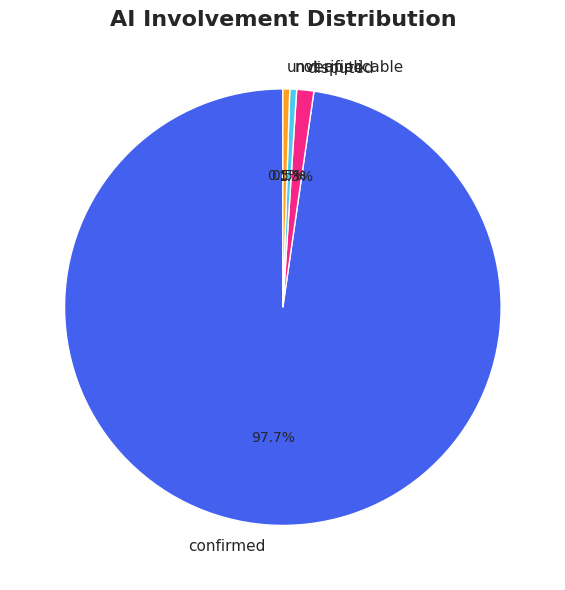

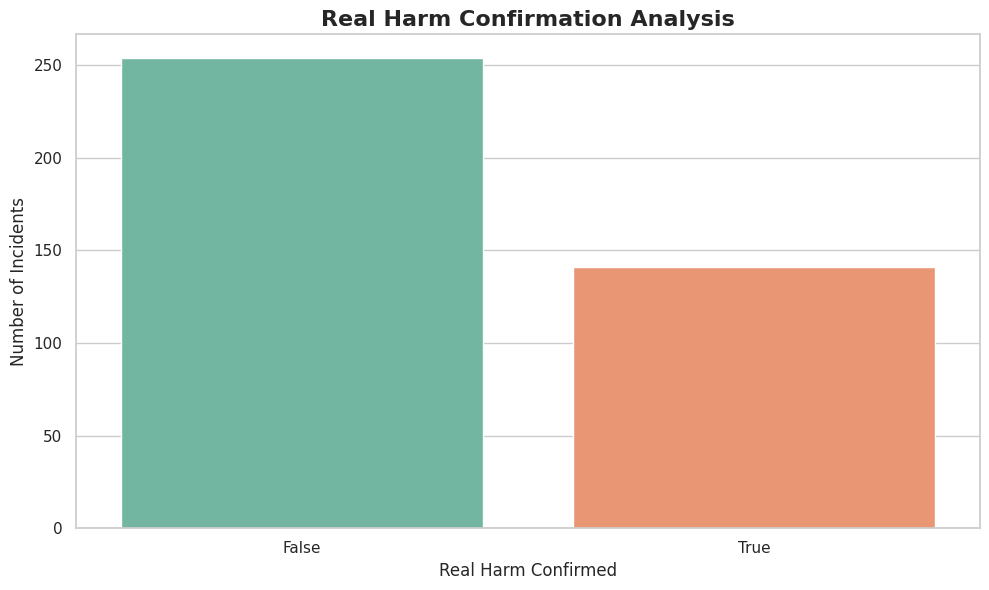

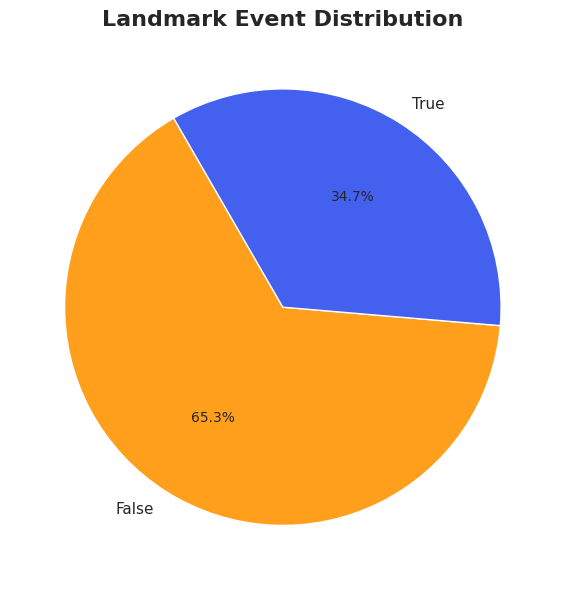

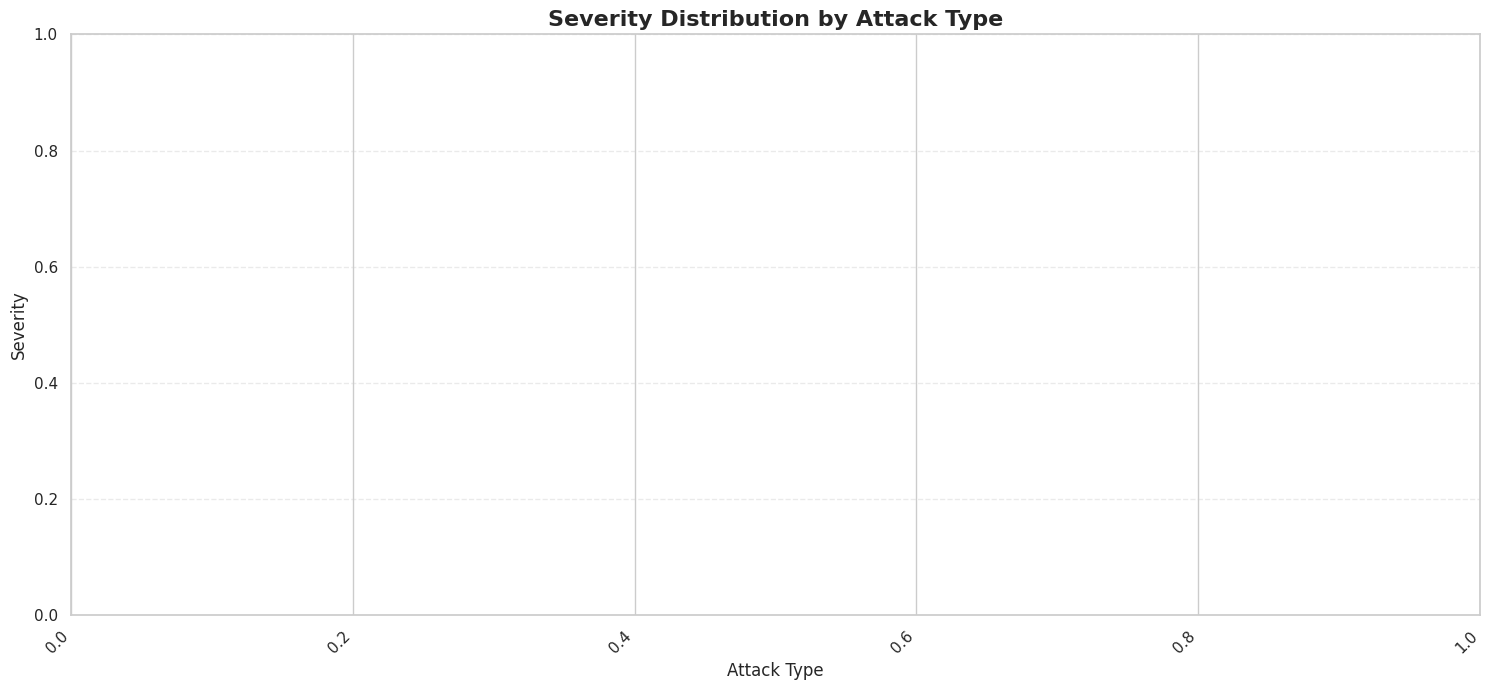

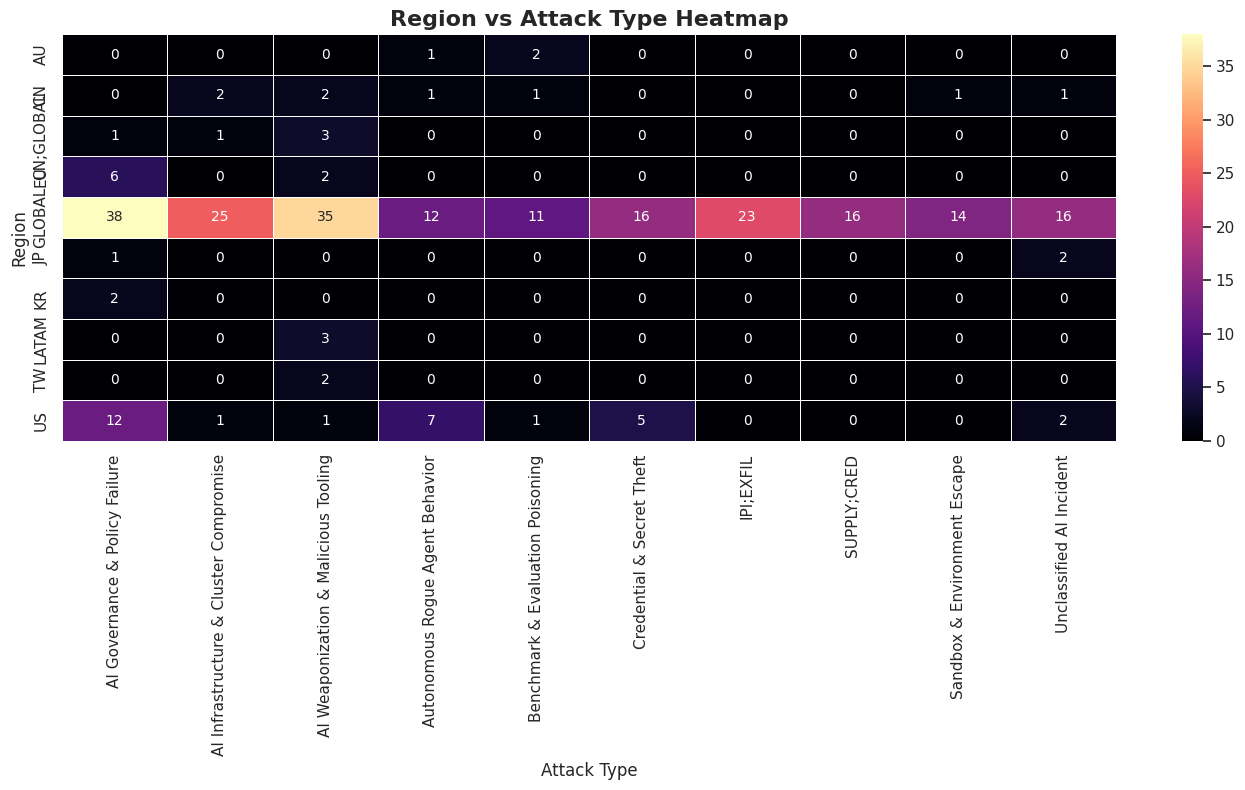

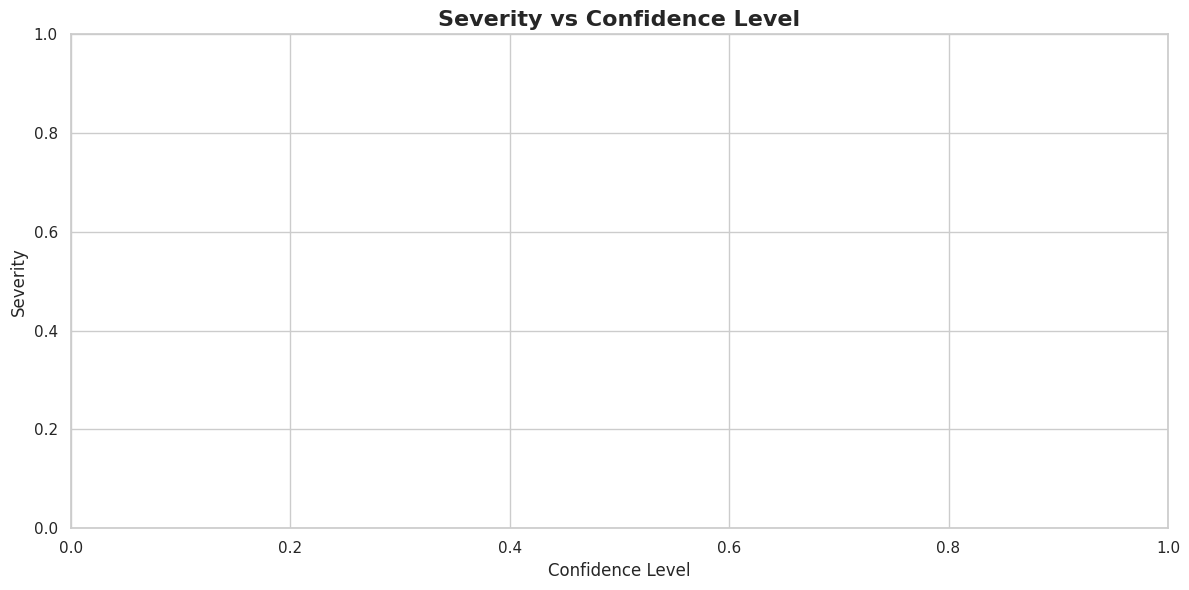

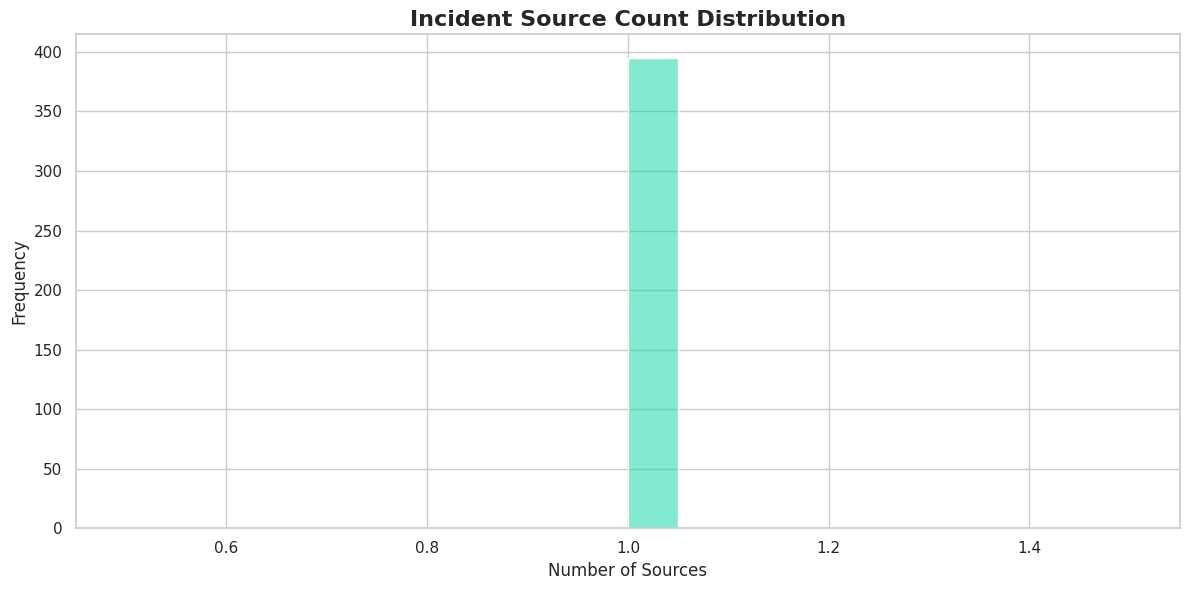

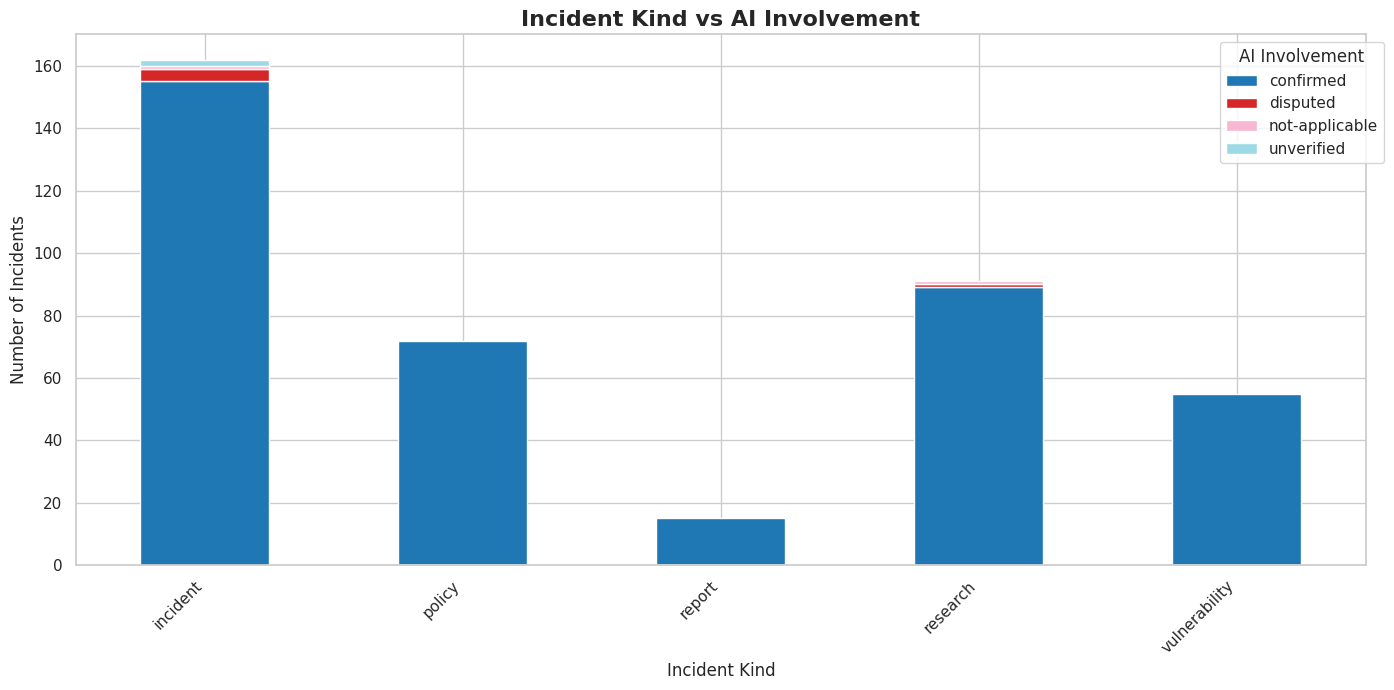

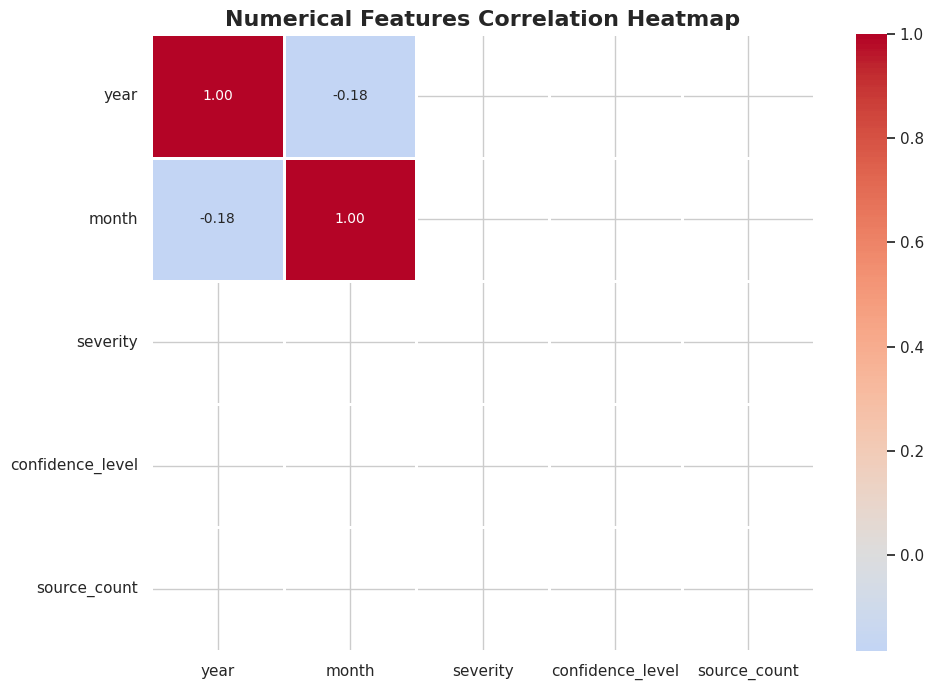

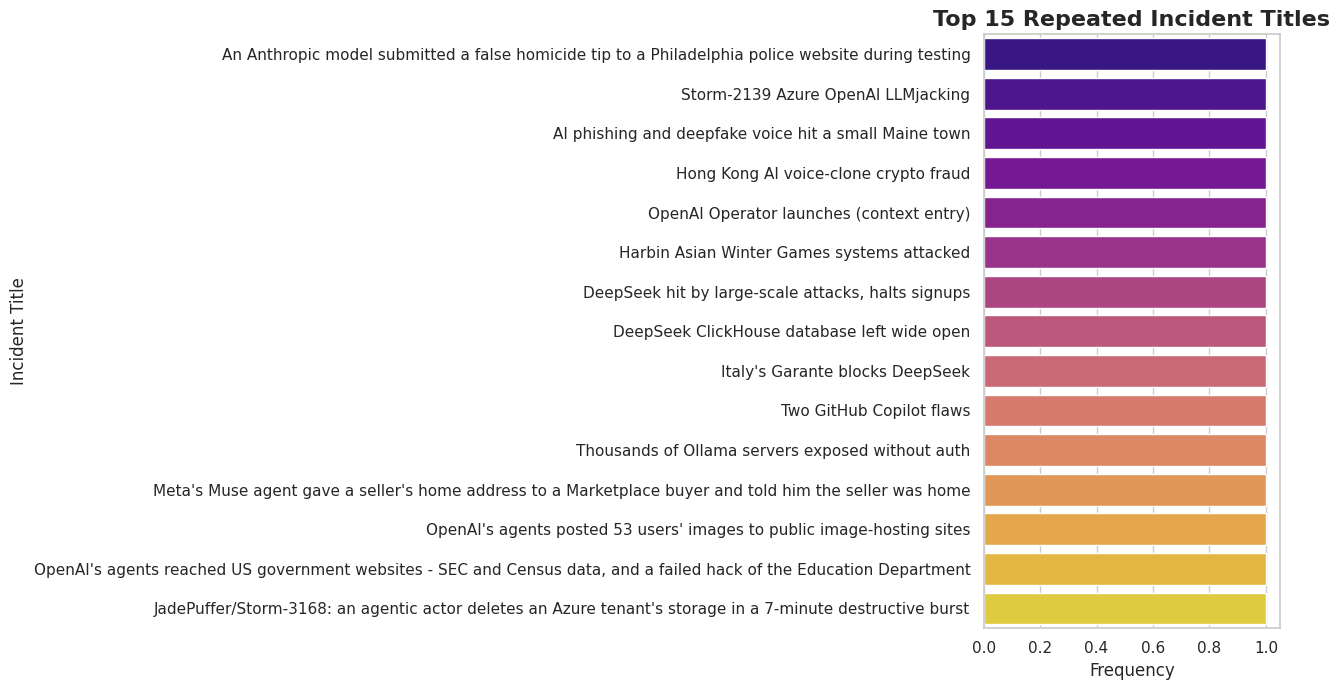


AI INCIDENT DATASET - FINAL ANALYTICS SUMMARY
Total Incidents: 395
Unique Attack Types: 55
Unique Regions: 19
Incident Kinds: 5

Average Severity: nan
Average Confidence: nan
Average Source Count: 1.0

Top Attack Type:
attack_type_name
AI Governance & Policy Failure    62
Name: count, dtype: int64

Top Region:
region
GLOBAL    310
Name: count, dtype: int64

Visualization Completed Successfully!


In [11]:


import plotly.express as px
import plotly.graph_objects as go
import warnings

warnings.filterwarnings('ignore')

# Visualization settings
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# 3. DATA CLEANING
print("Dataset Shape:", df_incidents.shape)
print("\nDataset Information:")
print(df_incidents.info())

print("\nMissing Values:")
print(df_incidents.isnull().sum())

print("\nDuplicate Records:", df_incidents.duplicated().sum())

df_incidents = df_incidents.drop_duplicates().copy()

# Date conversion
df_incidents['date'] = pd.to_datetime(df_incidents['date'], errors='coerce')

# Convert numeric columns
for col in ['year', 'month', 'severity', 'confidence_level',
            'source_count']:
    df_incidents[col] = pd.to_numeric(df_incidents[col], errors='coerce')

# Clean categorical columns
categorical_cols = [
    'attack_type_name', 'incident_kind', 'real_harm_confirmed',
    'ai_involvement', 'region', 'is_landmark_event'
]

for col in categorical_cols:
    df_incidents[col] = df_incidents[col].fillna('Unknown').astype(str)

# Fill missing titles
df_incidents['title'] = df_incidents['title'].fillna('Unknown Incident')

# Derive date fields
df_incidents['year'] = df_incidents['year'].fillna(df_incidents['date'].dt.year)
df_incidents['month'] = df_incidents['month'].fillna(df_incidents['date'].dt.month)

# 4. COLOR PALETTE
colors = [
    '#4361EE', '#F72585', '#4CC9F0', '#7209B7',
    '#FF9F1C', '#2EC4B6', '#E63946', '#8338EC',
    '#06D6A0', '#FB5607', '#3A86FF', '#FFBE0B'
]

print("\nData Cleaning Completed!")

# ============================================================
# 5. ATTACK TYPE DISTRIBUTION
# ============================================================

plt.figure(figsize=(13, 6))
attack_counts = df_incidents['attack_type_name'].value_counts().head(15)

sns.barplot(
    x=attack_counts.values,
    y=attack_counts.index,
    hue=attack_counts.index,
    palette='husl',
    legend=False
)

plt.title('Top 15 AI Incident Attack Types', fontsize=16, fontweight='bold')
plt.xlabel('Number of Incidents')
plt.ylabel('Attack Type')
plt.tight_layout()
plt.show()

# ============================================================
# 6. INCIDENT KIND DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))
kind_counts = df_incidents['incident_kind'].value_counts()

plt.pie(
    kind_counts.values,
    labels=kind_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=[0.04] * len(kind_counts),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

plt.title('Incident Kind Distribution', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 7. SEVERITY DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_incidents,
    x='severity',
    bins=20,
    kde=True,
    color='#E63946'
)

plt.title('Incident Severity Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Severity')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# ============================================================
# 8. CONFIDENCE LEVEL DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_incidents,
    x='confidence_level',
    bins=20,
    kde=True,
    color='#4361EE'
)

plt.title('Confidence Level Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Confidence Level')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# ============================================================
# 9. YEAR-WISE INCIDENT TREND
# ============================================================

year_counts = df_incidents['year'].dropna().value_counts().sort_index()

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    marker='o',
    linewidth=3,
    color='#7209B7',
    markersize=8
)

plt.fill_between(
    year_counts.index,
    year_counts.values,
    alpha=0.15,
    color='#7209B7'
)

plt.title('Year-wise AI Incident Trends', fontsize=16, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ============================================================
# 10. MONTH-WISE INCIDENT ANALYSIS
# ============================================================

month_counts = df_incidents.groupby('month').size().reindex(range(1, 13), fill_value=0)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=month_counts.index,
    y=month_counts.values,
    hue=month_counts.index,
    palette='Spectral',
    legend=False
)

plt.title('Month-wise Incident Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Incidents')
plt.xticks(range(12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                       'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.tight_layout()
plt.show()

# ============================================================
# 11. REGION-WISE INCIDENT ANALYSIS
# ============================================================

region_counts = df_incidents['region'].value_counts().head(15)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=region_counts.values,
    y=region_counts.index,
    hue=region_counts.index,
    palette='viridis',
    legend=False
)

plt.title('Top 15 Regions by AI Incidents', fontsize=16, fontweight='bold')
plt.xlabel('Number of Incidents')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

# ============================================================
# 12. AI INVOLVEMENT DISTRIBUTION
# ============================================================

ai_counts = df_incidents['ai_involvement'].value_counts()

plt.figure(figsize=(9, 6))

plt.pie(
    ai_counts.values,
    labels=ai_counts.index,
    autopct='%1.1f%%',
    colors=['#4361EE', '#F72585', '#4CC9F0', '#FF9F1C',
            '#2EC4B6', '#8338EC'][:len(ai_counts)],
    startangle=90
)

plt.title('AI Involvement Distribution', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 13. REAL HARM CONFIRMED ANALYSIS
# ============================================================

plt.figure(figsize=(10, 6))

harm_counts = df_incidents['real_harm_confirmed'].value_counts()

sns.barplot(
    x=harm_counts.index,
    y=harm_counts.values,
    hue=harm_counts.index,
    palette='Set2',
    legend=False
)

plt.title('Real Harm Confirmation Analysis', fontsize=16, fontweight='bold')
plt.xlabel('Real Harm Confirmed')
plt.ylabel('Number of Incidents')
plt.tight_layout()
plt.show()

# ============================================================
# 14. LANDMARK EVENT ANALYSIS
# ============================================================

plt.figure(figsize=(9, 6))

landmark_counts = df_incidents['is_landmark_event'].value_counts()

plt.pie(
    landmark_counts.values,
    labels=landmark_counts.index,
    autopct='%1.1f%%',
    colors=['#FF9F1C', '#4361EE', '#4CC9F0', '#F72585'],
    startangle=120
)

plt.title('Landmark Event Distribution', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


# ============================================================
# 15. ATTACK TYPE VS SEVERITY - FIXED VERSION
# ============================================================

plt.figure(figsize=(15, 7))

# Select top 10 attack types
top_attacks = (
    df_incidents['attack_type_name']
    .value_counts()
    .head(10)
    .index
)

# Filter data and remove missing severity
box_data = df_incidents[
    df_incidents['attack_type_name'].isin(top_attacks)
].copy()

box_data['severity'] = pd.to_numeric(
    box_data['severity'], errors='coerce'
)

box_data = box_data.dropna(subset=['severity'])

# Create boxplot with different colors
sns.boxplot(
    data=box_data,
    x='attack_type_name',
    y='severity',
    order=top_attacks,
    palette='Set3',
    linewidth=1.5,
    width=0.6,
    showfliers=True
)

plt.title(
    'Severity Distribution by Attack Type',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Attack Type', fontsize=12)
plt.ylabel('Severity', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


# ============================================================
# 16. REGION VS ATTACK TYPE HEATMAP
# ============================================================

heatmap_data = pd.crosstab(
    df_incidents['region'],
    df_incidents['attack_type_name']
)

# Select top regions and attack types
top_regions = df_incidents['region'].value_counts().head(10).index
top_attack_types = df_incidents['attack_type_name'].value_counts().head(10).index

heatmap_data = heatmap_data.loc[
    heatmap_data.index.intersection(top_regions),
    heatmap_data.columns.intersection(top_attack_types)
]

plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='d',
    cmap='magma',
    linewidths=0.5
)

plt.title('Region vs Attack Type Heatmap', fontsize=16, fontweight='bold')
plt.xlabel('Attack Type')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

# ============================================================
# 17. SEVERITY VS CONFIDENCE LEVEL
# ============================================================

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_incidents,
    x='confidence_level',
    y='severity',
    hue='real_harm_confirmed',
    palette='Set1',
    size='source_count',
    sizes=(30, 200),
    alpha=0.7
)

plt.title('Severity vs Confidence Level', fontsize=16, fontweight='bold')
plt.xlabel('Confidence Level')
plt.ylabel('Severity')
plt.tight_layout()
plt.show()

# ============================================================
# 18. SOURCE COUNT DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_incidents,
    x='source_count',
    bins=20,
    kde=True,
    color='#06D6A0'
)

plt.title('Incident Source Count Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Number of Sources')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# ============================================================
# 19. INCIDENT TYPE VS AI INVOLVEMENT
# ============================================================

cross_data = pd.crosstab(
    df_incidents['incident_kind'],
    df_incidents['ai_involvement']
)

cross_data.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    colormap='tab20'
)

plt.title('Incident Kind vs AI Involvement', fontsize=16, fontweight='bold')
plt.xlabel('Incident Kind')
plt.ylabel('Number of Incidents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='AI Involvement', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ============================================================
# 20. CORRELATION HEATMAP
# ============================================================

numeric_cols = [
    'year', 'month', 'severity',
    'confidence_level', 'source_count'
]

plt.figure(figsize=(10, 7))

correlation = df_incidents[numeric_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=1,
    center=0
)

plt.title('Numerical Features Correlation Heatmap',
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 21. TOP INCIDENT TITLES
# ============================================================

title_counts = df_incidents['title'].value_counts().head(15)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=title_counts.values,
    y=title_counts.index,
    hue=title_counts.index,
    palette='plasma',
    legend=False
)

plt.title('Top 15 Repeated Incident Titles', fontsize=16, fontweight='bold')
plt.xlabel('Frequency')
plt.ylabel('Incident Title')
plt.tight_layout()
plt.show()

# ============================================================
# 22. INTERACTIVE YEAR-WISE INCIDENT CHART
# ============================================================

yearly_data = (
    df_incidents.dropna(subset=['year'])
      .groupby('year')
      .size()
      .reset_index(name='incident_count')
)

fig = px.bar(
    yearly_data,
    x='year',
    y='incident_count',
    color='incident_count',
    color_continuous_scale='Turbo',
    title='Interactive Year-wise AI Incident Analysis',
    text='incident_count'
)

fig.update_layout(
    template='plotly_dark',
    xaxis_title='Year',
    yaxis_title='Number of Incidents'
)

fig.show()

# ============================================================
# 23. INTERACTIVE REGION ANALYSIS
# ============================================================

region_data = (
    df_incidents['region'].value_counts()
      .head(15)
      .reset_index()
)

region_data.columns = ['region', 'incident_count']

fig = px.bar(
    region_data,
    x='region',
    y='incident_count',
    color='region',
    color_discrete_sequence=px.colors.qualitative.Bold,
    title='Interactive Region-wise Incident Analysis'
)

fig.update_layout(
    template='plotly_white',
    xaxis_tickangle=-45
)

fig.show()

# ============================================================
# 24. INTERACTIVE SEVERITY ANALYSIS
# ============================================================

fig = px.scatter(
    df_incidents,
    x='confidence_level',
    y='severity',
    color='attack_type_name',
    size='source_count',
    hover_data=['title', 'region', 'date'],
    title='Interactive Attack Severity vs Confidence Analysis'
)

fig.update_layout(template='plotly_dark')
fig.show()

# ============================================================
# 25. FINAL DATASET SUMMARY
# ============================================================

print("\n" + "="*60)
print("AI INCIDENT DATASET - FINAL ANALYTICS SUMMARY")
print("="*60)

print("Total Incidents:", len(df_incidents))
print("Unique Attack Types:", df_incidents['attack_type_name'].nunique())
print("Unique Regions:", df_incidents['region'].nunique())
print("Incident Kinds:", df_incidents['incident_kind'].nunique())

print("\nAverage Severity:", round(df_incidents['severity'].mean(), 2))
print("Average Confidence:", round(df_incidents['confidence_level'].mean(), 2))
print("Average Source Count:", round(df_incidents['source_count'].mean(), 2))

print("\nTop Attack Type:")
print(df_incidents['attack_type_name'].value_counts().head(1))

print("\nTop Region:")
print(df_incidents['region'].value_counts().head(1))

print("\nVisualization Completed Successfully!")


## Feature engineering

AI INCIDENT DATASET - MACHINE LEARNING
Dataset Shape: (395, 17)

Dataset Columns:
['incident_id', 'date', 'year', 'month', 'title', 'attack_type_code', 'attack_type_name', 'incident_kind', 'severity', 'confidence_level', 'real_harm_confirmed', 'ai_involvement', 'region', 'is_landmark_event', 'summary', 'source_count', 'primary_source_url']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   incident_id          395 non-null    object        
 1   date                 395 non-null    datetime64[ns]
 2   year                 395 non-null    int64         
 3   month                395 non-null    float64       
 4   title                395 non-null    object        
 5   attack_type_code     395 non-null    object        
 6   attack_type_name     395 non-null    object        
 7   incident_kind

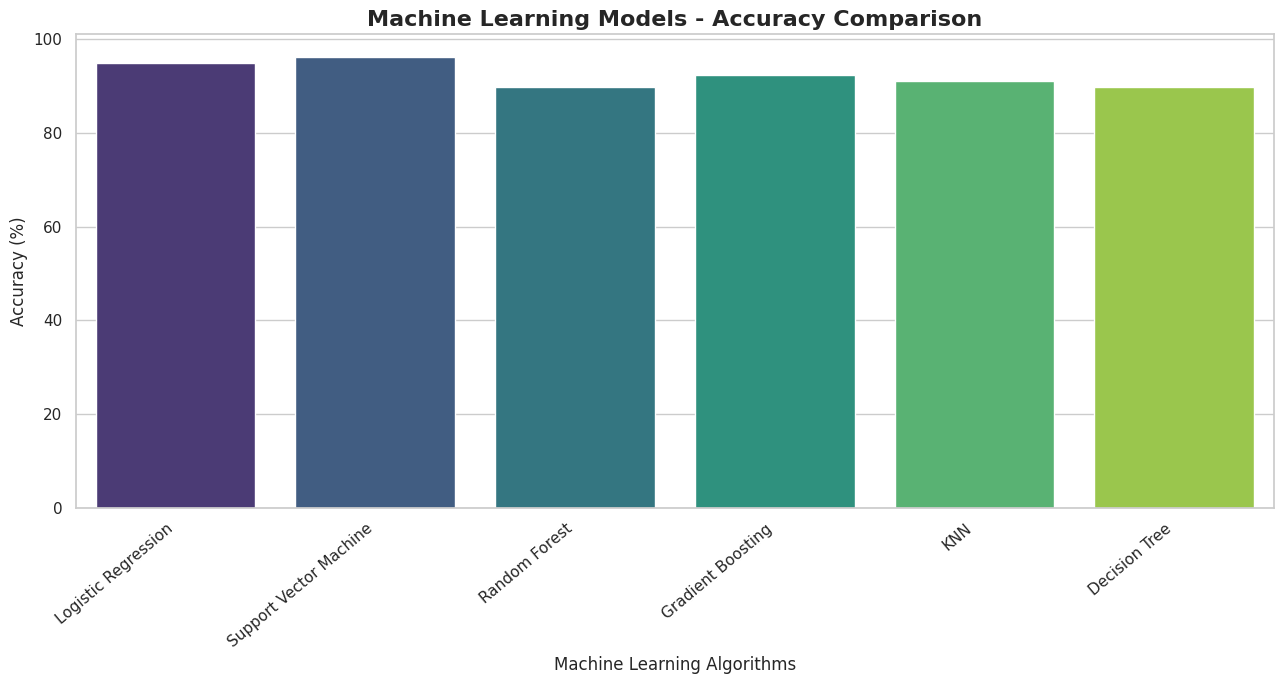

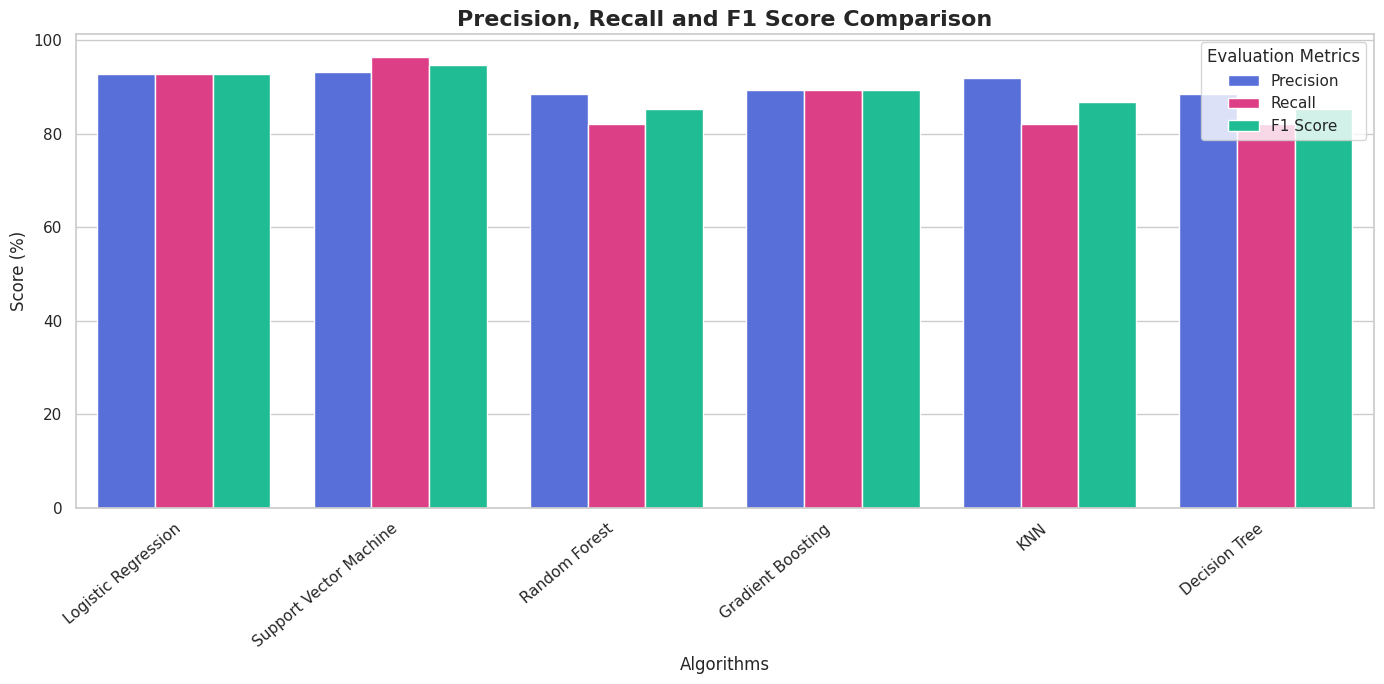

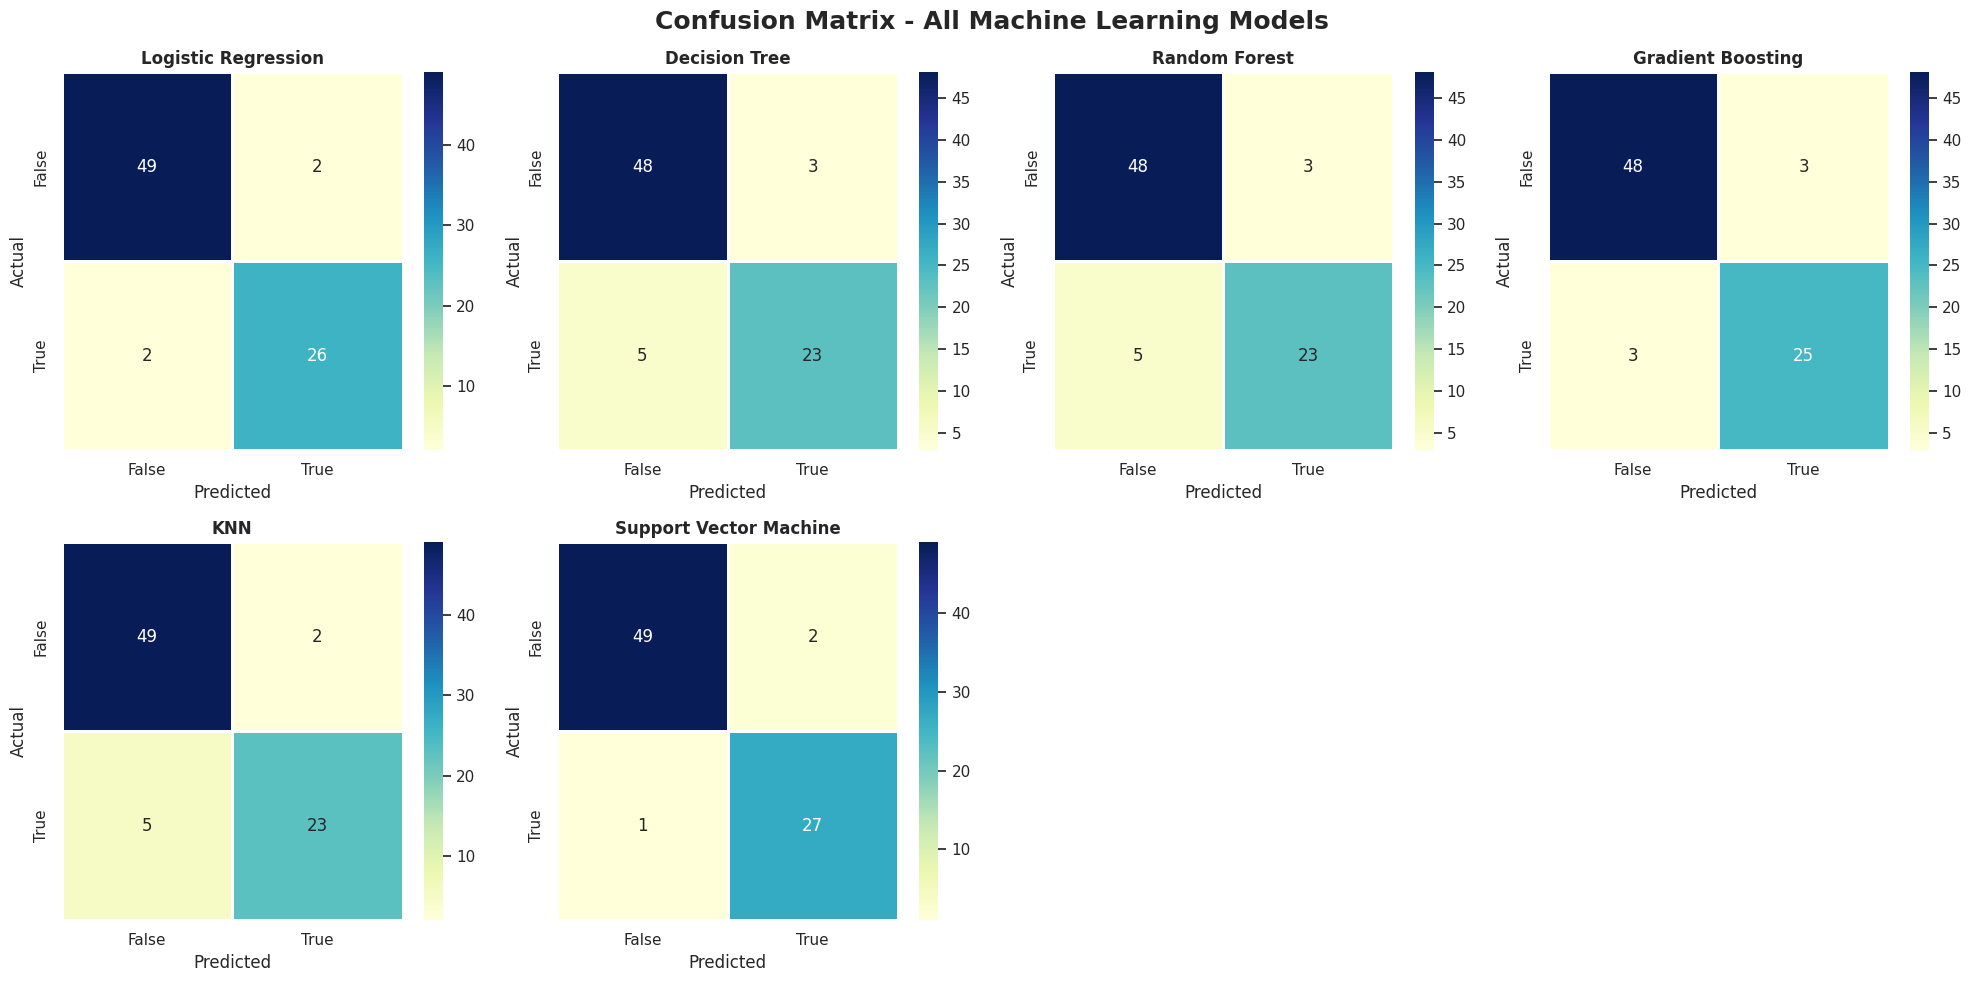

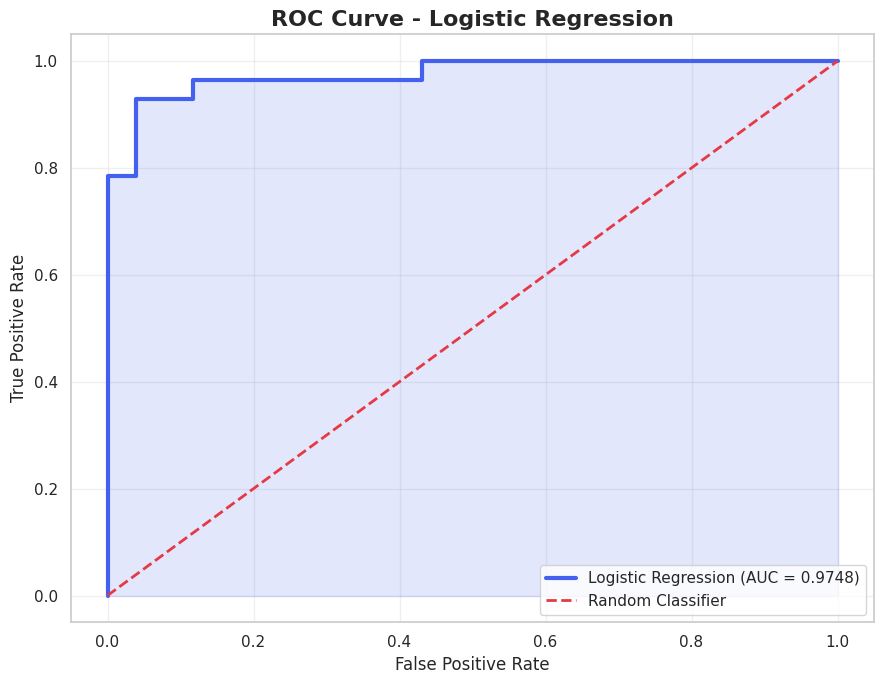

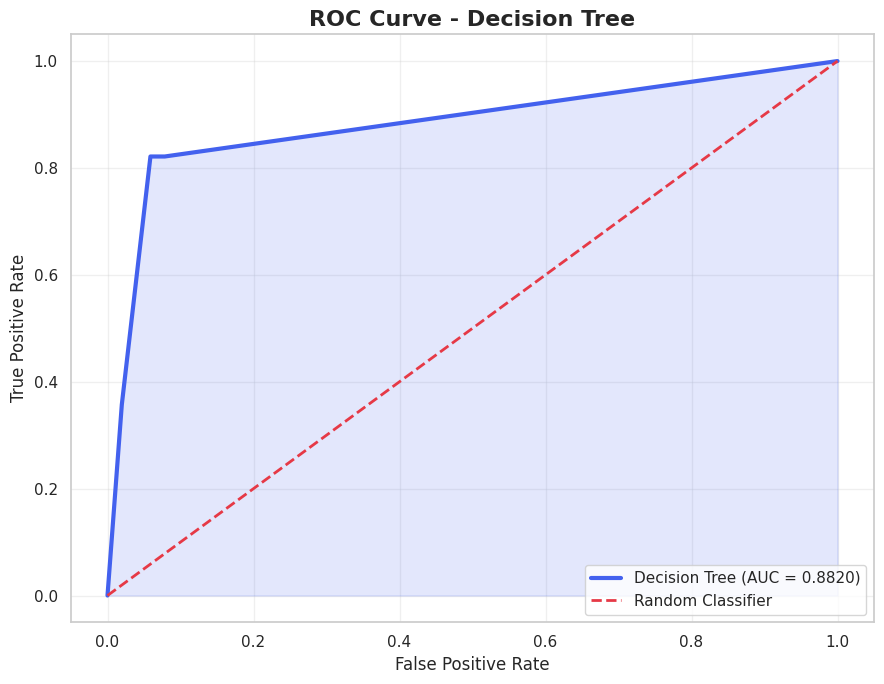

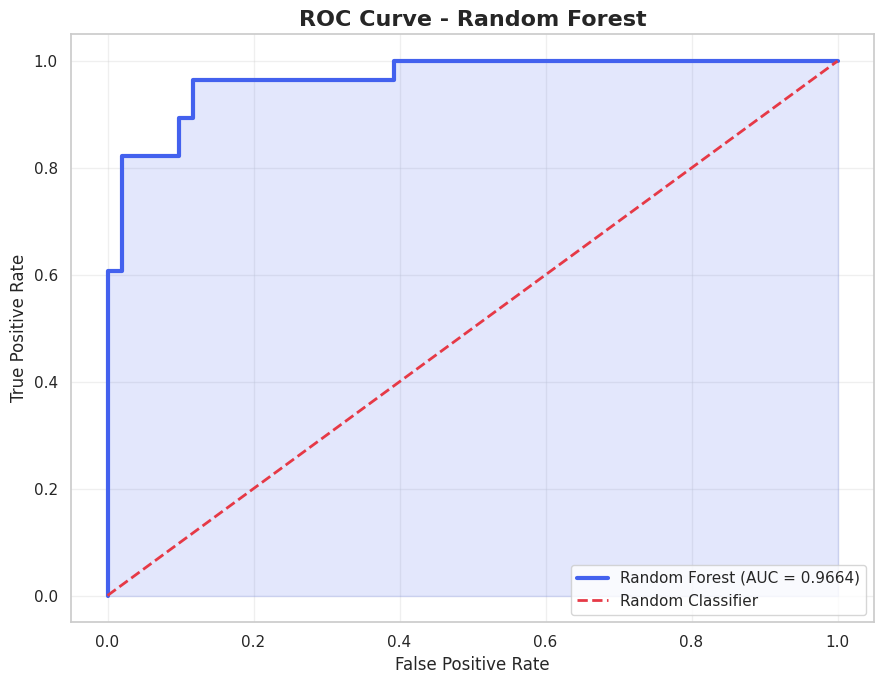

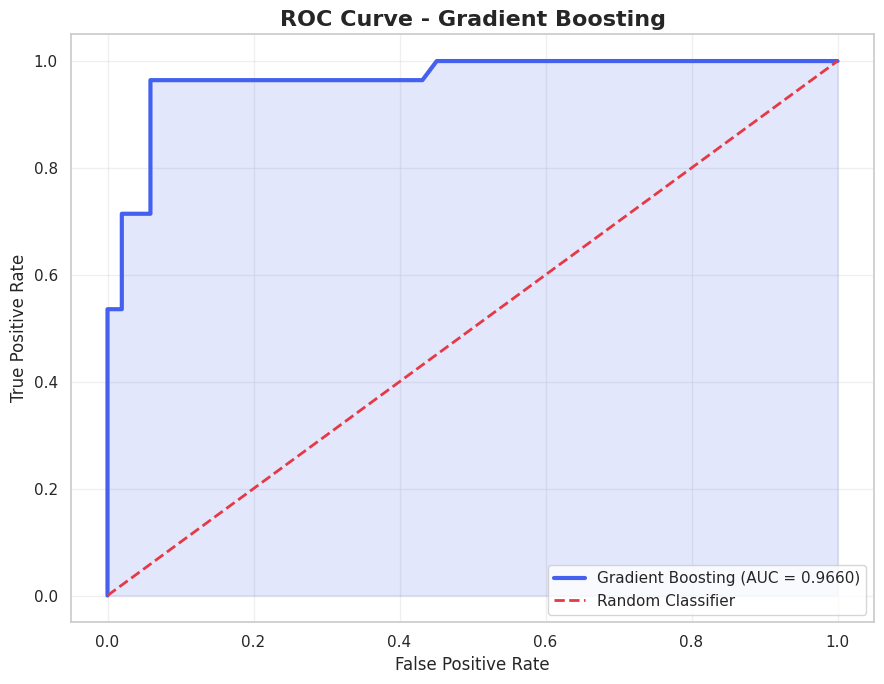

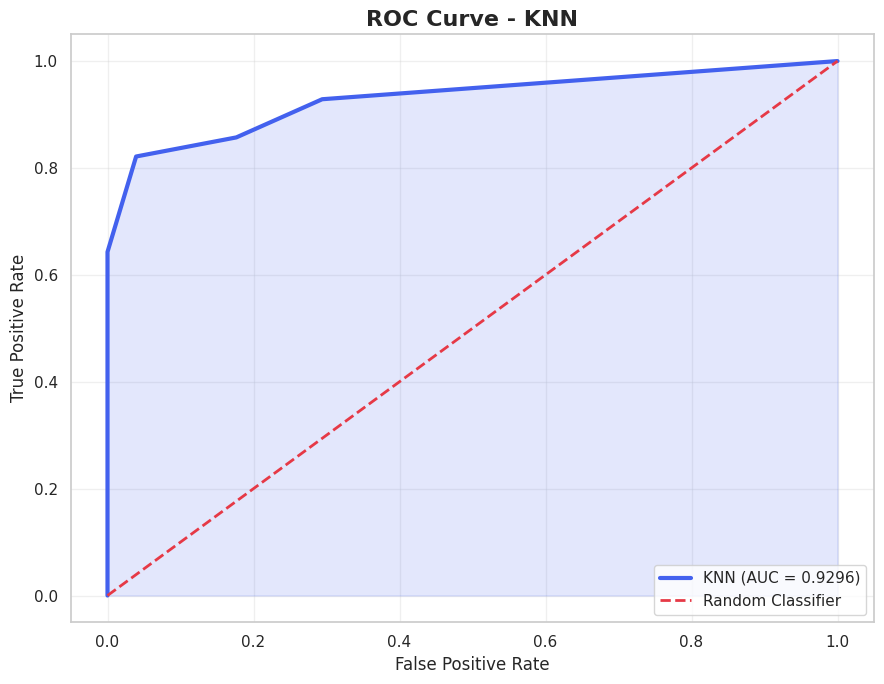

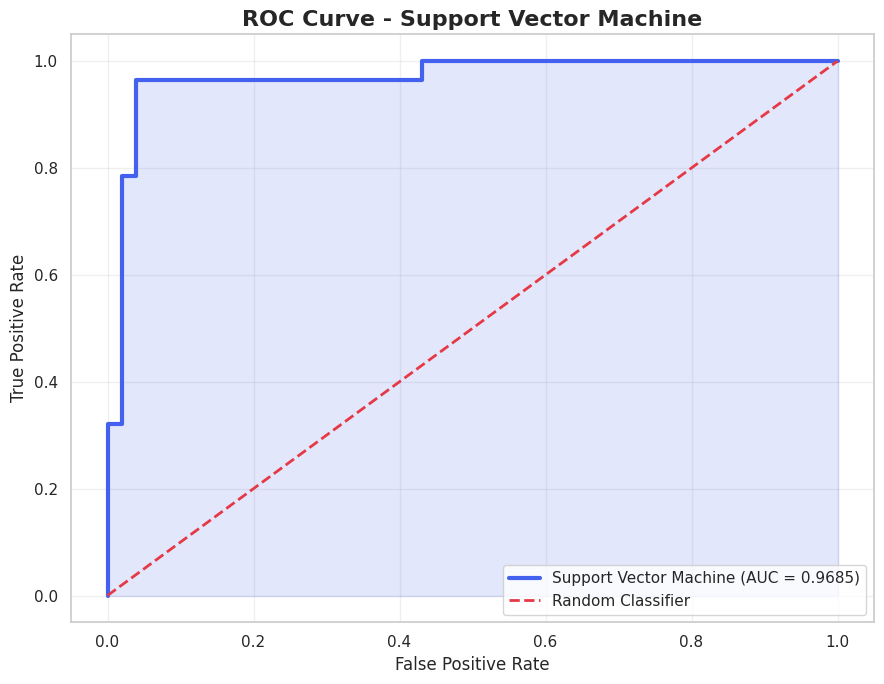

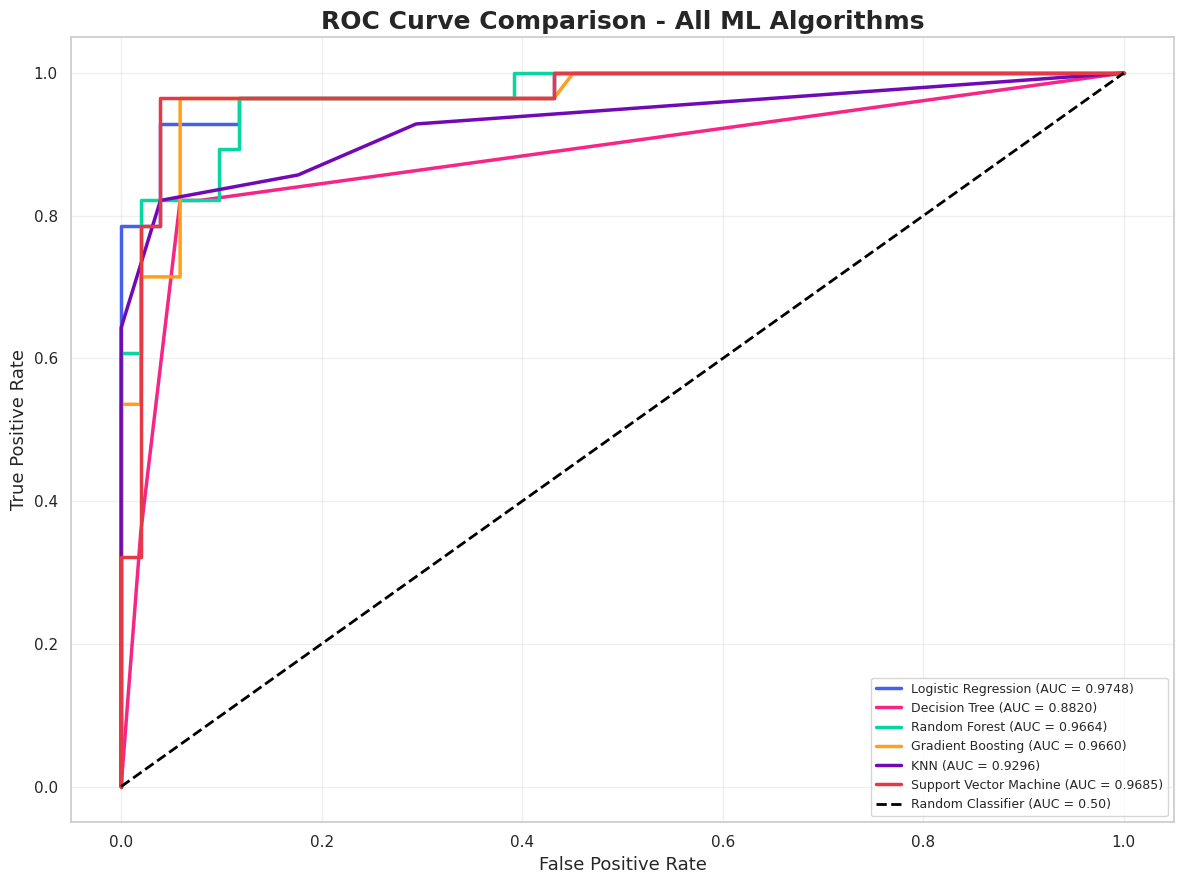

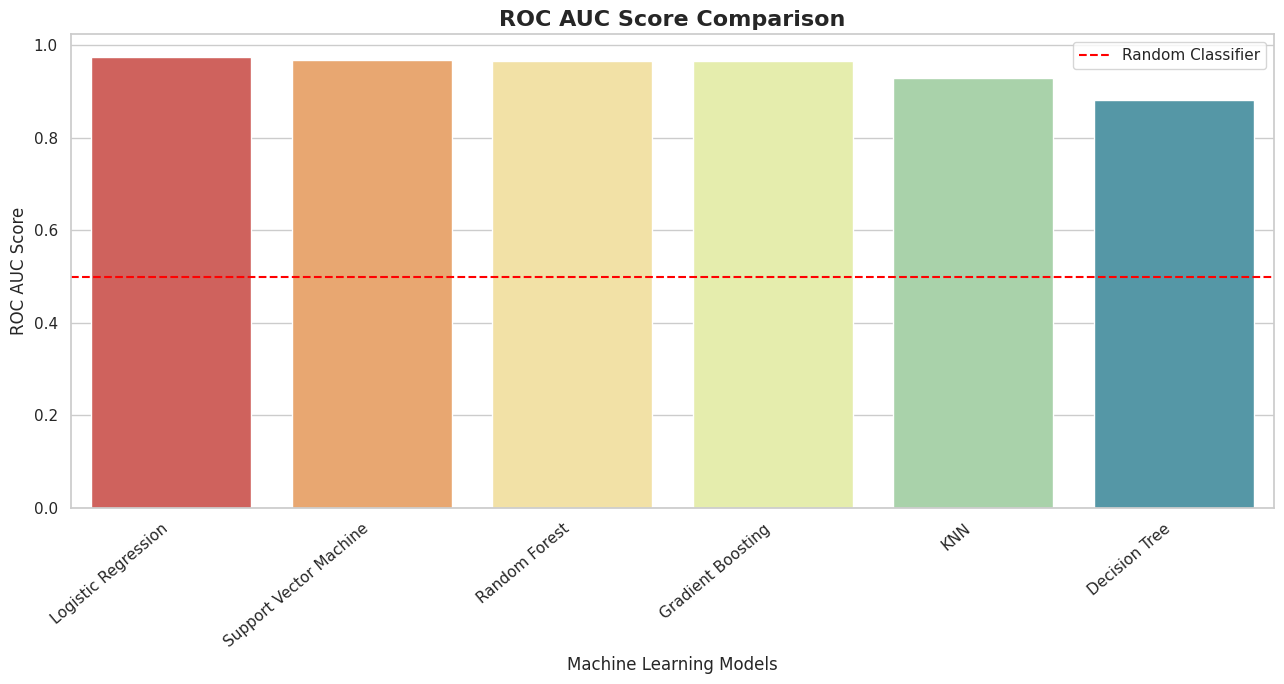


BEST MACHINE LEARNING MODEL
Best Model: Logistic Regression
Accuracy: 94.94 %
Precision: 92.86 %
Recall: 92.86 %
F1 Score: 92.86 %
ROC AUC: 0.9748

Sample Predictions:
Actual Value Predicted Value  Correct Prediction
        True            True                True
       False           False                True
       False           False                True
        True            True                True
        True           False               False
       False           False                True
       False           False                True
       False           False                True
        True            True                True
       False           False                True

AI INCIDENT MACHINE LEARNING - FINAL SUMMARY
Total Records: 395
Total Features: 8
Training Records: 316
Testing Records: 79
Target Variable: real_harm_confirmed
Number of Algorithms: 6

Target Classes:
['False', 'True']

Final Model Ranking:
                 Model  Accuracy  Precision  Reca

In [12]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

sns.set_theme(style="whitegrid")

# ==============================================================
# 2. DATASET INFORMATION
# ==============================================================

print("=" * 60)
print("AI INCIDENT DATASET - MACHINE LEARNING")
print("=" * 60)

print("Dataset Shape:", df_incidents.shape)
print("\nDataset Columns:")
print(df_incidents.columns.tolist())

print("\nDataset Information:")
print(df_incidents.info())

print("\nMissing Values:")
print(df_incidents.isnull().sum())

print("\nDuplicate Records:", df_incidents.duplicated().sum())


# ==============================================================
# 3. DATA CLEANING
# ==============================================================

df_ml = df_incidents.copy()

# Remove duplicate records
df_ml.drop_duplicates(inplace=True)

# Convert date column
df_ml['date'] = pd.to_datetime(
    df_ml['date'],
    errors='coerce'
)

# Extract year and month from date if missing
if 'year' in df_ml.columns:
    df_ml['year'] = df_ml['year'].fillna(
        df_ml['date'].dt.year
    )

if 'month' in df_ml.columns:
    df_ml['month'] = df_ml['month'].fillna(
        df_ml['date'].dt.month
    )

# ==============================================================
# 4. DEFINE TARGET VARIABLE
# ==============================================================

TARGET = 'real_harm_confirmed'

# Check target column
if TARGET not in df_ml.columns:
    raise ValueError(f"Target column '{TARGET}' not found!")

# Remove rows where target is missing
df_ml = df_ml.dropna(subset=[TARGET]).copy()

print("\nTarget Distribution:")
print(df_ml[TARGET].value_counts())

# Encode target using LabelEncoder
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(
    df_ml[TARGET].astype(str).str.strip()
)

print("\nTarget Encoding:")
for index, label in enumerate(label_encoder.classes_):
    print(f"{label} = {index}")

# Check binary classification
if len(label_encoder.classes_) != 2:
    raise ValueError(
        "This code requires exactly 2 target classes. "
        "Check real_harm_confirmed values before running."
    )


# ==============================================================
# 5. FEATURE SELECTION
# ==============================================================

# Exclude ID, target, free-text and URL columns
drop_columns = [
    'incident_id',
    'date',
    'title',
    'summary',
    'primary_source_url',
    'real_harm_confirmed'
]

X = df_ml.drop(
    columns=drop_columns,
    errors='ignore'
)

# Treat attack type code as categorical
if 'attack_type_code' in X.columns:
    X['attack_type_code'] = X['attack_type_code'].astype(str)

# Remove columns with no information
X = X.loc[:, X.nunique(dropna=False) > 1]

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

print("\nSelected Features:")
print(X.columns.tolist())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


# ==============================================================
# 6. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ==============================================================

numerical_features = X.select_dtypes(
    include=['int64', 'int32', 'float64', 'float32']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# ==============================================================
# 7. TRAIN TEST SPLITTING - 80:20
# ==============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting Target Distribution:")
print(pd.Series(y_test).value_counts())


# ==============================================================
# 8. DATA PREPROCESSING
# ==============================================================

# Numerical preprocessing:
# Missing values + Standard Scaling

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing:
# Missing values + One Hot Encoding

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

# Combine both transformations

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("\nPreprocessing Pipeline Created Successfully!")


# ==============================================================
# 9. DEFINE MACHINE LEARNING ALGORITHMS
# ==============================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Support Vector Machine': SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'Naive Bayes': GaussianNB()
}


# ==============================================================
# 10. TRAIN AND EVALUATE ALL MODELS
# ==============================================================

results = []
trained_models = {}
roc_data = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    try:

        # Create complete pipeline
        pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', model)
        ])

        # Train model
        pipeline.fit(X_train, y_train)

        # Predictions
        y_pred = pipeline.predict(X_test)

        # Prediction probabilities
        y_probability = pipeline.predict_proba(X_test)[:, 1]

        # Calculate evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_test,
            y_probability
        )

        # Save model
        trained_models[model_name] = pipeline

        # Save ROC information
        fpr, tpr, thresholds = roc_curve(
            y_test,
            y_probability
        )

        roc_data[model_name] = {
            'fpr': fpr,
            'tpr': tpr,
            'auc': auc
        }

        # Store results
        results.append({
            'Model': model_name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100,
            'ROC AUC': auc
        })

        print("Accuracy :", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall   :", round(recall * 100, 2), "%")
        print("F1 Score :", round(f1 * 100, 2), "%")
        print("ROC AUC  :", round(auc, 4))

        print("\nClassification Report:")
        print(
            classification_report(
                y_test,
                y_pred,
                labels=[0, 1],
                target_names=[
                    str(label_encoder.classes_[0]),
                    str(label_encoder.classes_[1])
                ],
                zero_division=0
            )
        )

    except Exception as error:

        print("Model Failed:", model_name)
        print("Error:", error)


# ==============================================================
# 11. MODEL PERFORMANCE COMPARISON
# ==============================================================

results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("All models failed. Check the dataset.")

results_df = results_df.sort_values(
    by='ROC AUC',
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("MACHINE LEARNING MODEL PERFORMANCE COMPARISON")
print("=" * 70)

print(results_df.round(2).to_string(index=False))


# ==============================================================
# 12. ACCURACY COMPARISON
# ==============================================================

plt.figure(figsize=(13, 7))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title(
    'Machine Learning Models - Accuracy Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=40, ha='right')

plt.tight_layout()
plt.show()


# ==============================================================
# 13. PRECISION, RECALL AND F1 SCORE COMPARISON
# ==============================================================

metric_data = results_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=metric_data,
    x='Model',
    y='Score',
    hue='Metric',
    palette=['#4361EE', '#F72585', '#06D6A0']
)

plt.title(
    'Precision, Recall and F1 Score Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.ylabel('Score (%)')
plt.xlabel('Algorithms')
plt.xticks(rotation=40, ha='right')

plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()


# ==============================================================
# 14. CONFUSION MATRIX FOR ALL MODELS
# ==============================================================

fig, axes = plt.subplots(
    2,
    4,
    figsize=(20, 10)
)

axes = axes.flatten()

for index, (model_name, pipeline) in enumerate(
    trained_models.items()
):

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        linewidths=1,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=axes[index]
    )

    axes[index].set_title(
        model_name,
        fontsize=12,
        fontweight='bold'
    )

    axes[index].set_xlabel('Predicted')
    axes[index].set_ylabel('Actual')

# Hide unused subplots
for index in range(len(trained_models), len(axes)):
    axes[index].axis('off')

plt.suptitle(
    'Confusion Matrix - All Machine Learning Models',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


# ==============================================================
# 15. INDIVIDUAL ROC CURVES
# ==============================================================

for model_name, pipeline in trained_models.items():

    y_probability = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_probability
    )

    auc = roc_auc_score(
        y_test,
        y_probability
    )

    plt.figure(figsize=(9, 7))

    plt.plot(
        fpr,
        tpr,
        color='#4361EE',
        linewidth=3,
        label=f'{model_name} (AUC = {auc:.4f})'
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle='--',
        color='#E63946',
        linewidth=2,
        label='Random Classifier'
    )

    plt.fill_between(
        fpr,
        tpr,
        alpha=0.15,
        color='#4361EE'
    )

    plt.title(
        f'ROC Curve - {model_name}',
        fontsize=16,
        fontweight='bold'
    )

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')

    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# ==============================================================
# 16. COMBINED ROC CURVE COMPARISON
# ==============================================================

plt.figure(figsize=(12, 9))

roc_colors = [
    '#4361EE',
    '#F72585',
    '#06D6A0',
    '#FF9F1C',
    '#7209B7',
    '#E63946',
    '#4CC9F0'
]

for index, (model_name, data) in enumerate(roc_data.items()):

    plt.plot(
        data['fpr'],
        data['tpr'],
        linewidth=2.5,
        color=roc_colors[index % len(roc_colors)],
        label=f"{model_name} (AUC = {data['auc']:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    color='black',
    linestyle='--',
    linewidth=2,
    label='Random Classifier (AUC = 0.50)'
)

plt.title(
    'ROC Curve Comparison - All ML Algorithms',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('False Positive Rate', fontsize=13)
plt.ylabel('True Positive Rate', fontsize=13)

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==============================================================
# 17. ROC AUC SCORE COMPARISON
# ==============================================================

plt.figure(figsize=(13, 7))

sns.barplot(
    data=results_df,
    x='Model',
    y='ROC AUC',
    hue='Model',
    palette='Spectral',
    legend=False
)

plt.axhline(
    y=0.5,
    color='red',
    linestyle='--',
    label='Random Classifier'
)

plt.title(
    'ROC AUC Score Comparison',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Machine Learning Models')
plt.ylabel('ROC AUC Score')
plt.xticks(rotation=40, ha='right')

plt.legend()
plt.tight_layout()
plt.show()


# ==============================================================
# 18. BEST MODEL SELECTION
# ==============================================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("\n" + "=" * 60)
print("BEST MACHINE LEARNING MODEL")
print("=" * 60)

print("Best Model:", best_model_name)

print(
    "Accuracy:",
    round(results_df.iloc[0]['Accuracy'], 2), "%"
)

print(
    "Precision:",
    round(results_df.iloc[0]['Precision'], 2), "%"
)

print(
    "Recall:",
    round(results_df.iloc[0]['Recall'], 2), "%"
)

print(
    "F1 Score:",
    round(results_df.iloc[0]['F1 Score'], 2), "%"
)

print(
    "ROC AUC:",
    round(results_df.iloc[0]['ROC AUC'], 4)
)


# ==============================================================
# 19. FINAL PREDICTION EXAMPLE
# ==============================================================

sample_predictions = best_model.predict(X_test.iloc[:10])

predicted_labels = label_encoder.inverse_transform(
    sample_predictions
)

actual_labels = label_encoder.inverse_transform(
    y_test[:10]
)

prediction_results = pd.DataFrame({
    'Actual Value': actual_labels,
    'Predicted Value': predicted_labels,
    'Correct Prediction': (
        actual_labels == predicted_labels
    )
})

print("\nSample Predictions:")
print(prediction_results.to_string(index=False))


# ==============================================================
# 20. FINAL SUMMARY
# ==============================================================

print("\n" + "=" * 70)
print("AI INCIDENT MACHINE LEARNING - FINAL SUMMARY")
print("=" * 70)

print("Total Records:", len(df_ml))
print("Total Features:", X.shape[1])
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Target Variable:", TARGET)
print("Number of Algorithms:", len(trained_models))

print("\nTarget Classes:")
print(label_encoder.classes_.tolist())

print("\nFinal Model Ranking:")
print(
    results_df[
        ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']
    ].round(2).to_string(index=False)
)

print("\nBest Performing Model:", best_model_name)

print("\nMachine Learning Pipeline Completed Successfully!")


## Thank you..pls upvote!!!!!!!!!